Name: Shourya Chilate

Section: B1

Batch: B4

Roll No: 58

Load Dataset Using Pandas

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('insurance.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)


Dataset loaded successfully!
Shape: (1338, 7)


head() shows the first five records, while tail() shows the last five records

In [2]:

print("First 5 rows:")
display(df.head())

print("Last 5 rows:")
display(df.tail())

First 5 rows:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Last 5 rows:


,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


 Display dataset dimensions

In [3]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1338
Number of columns: 7


In [4]:
# Display all column names
print("Column names:")
print(df.columns.tolist())

Column names:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


In [5]:
# Display data type of each column
print(df.dtypes)

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


In [6]:
# Display dataset structure and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


Checking Missing Values

In [7]:
# Count missing values in each column
print(df.isnull().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


No Missing Values

In [8]:
# Count duplicate rows
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 1


 Identify numerical columns

 Identify categorical columns

In [10]:

num_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Numerical variables:", num_cols)

cat_cols = df.select_dtypes(include='object').columns.tolist()
print("Categorical variables:", cat_cols)

Numerical variables: ['age', 'bmi', 'children', 'charges']
Categorical variables: ['sex', 'smoker', 'region']


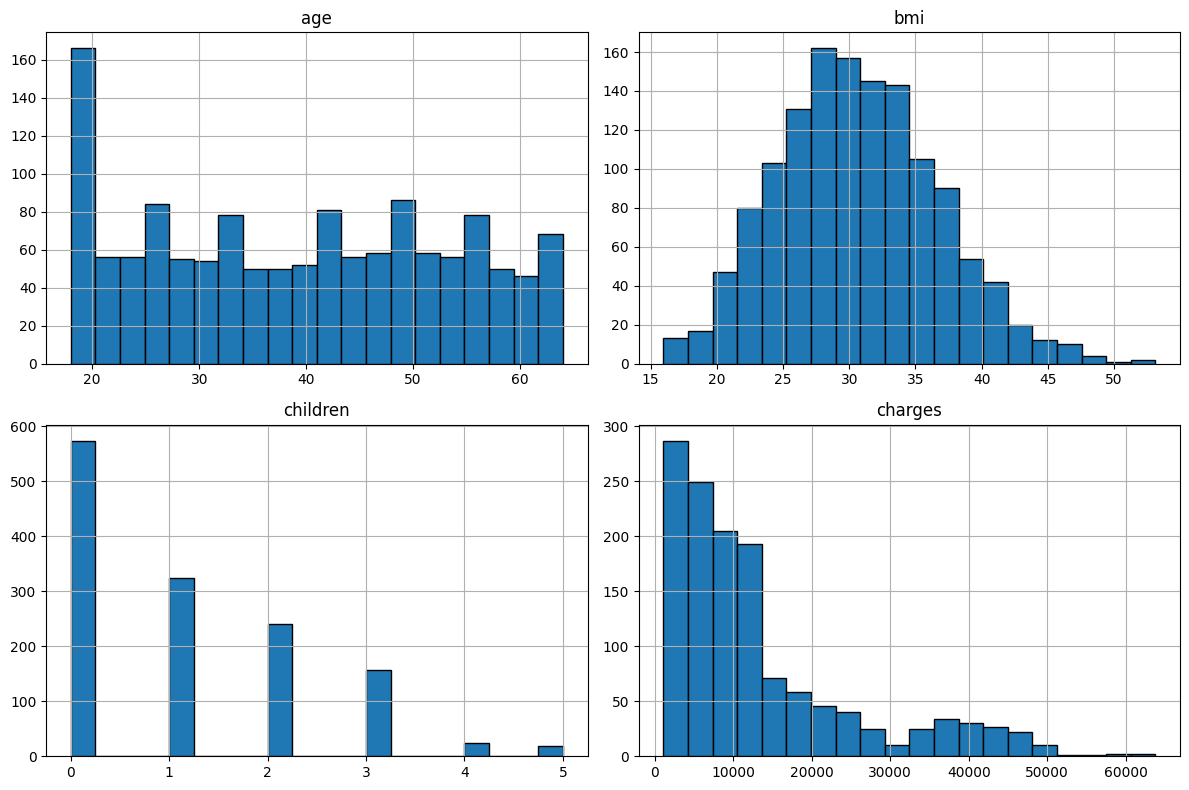

In [11]:
# Plot distributions of numerical variables
df[num_cols].hist(figsize=(12, 8), bins=20, edgecolor='black')
plt.tight_layout()
plt.show()

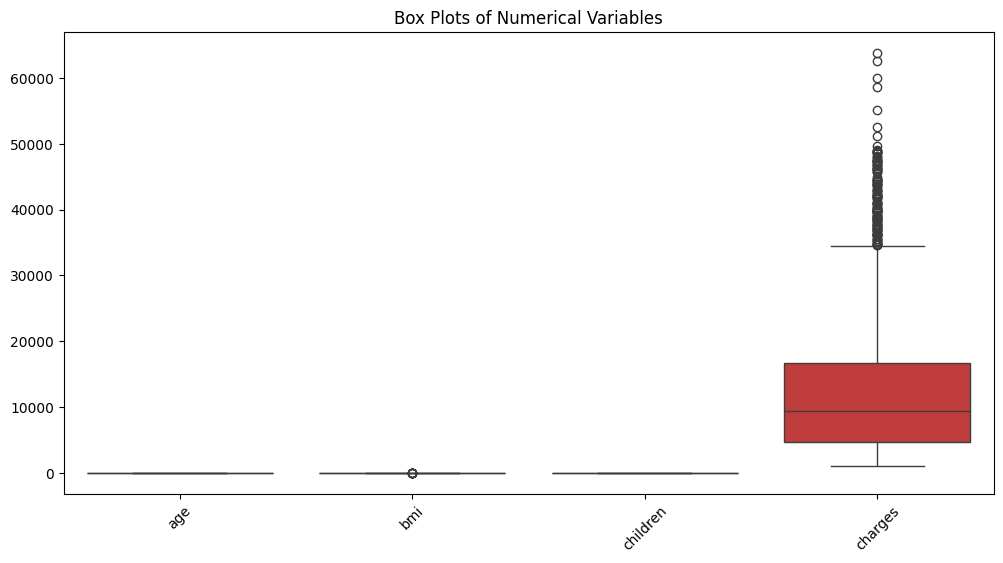

In [12]:
# Display box plots for numerical variables
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[num_cols])
plt.xticks(rotation=45)
plt.title("Box Plots of Numerical Variables")
plt.show()

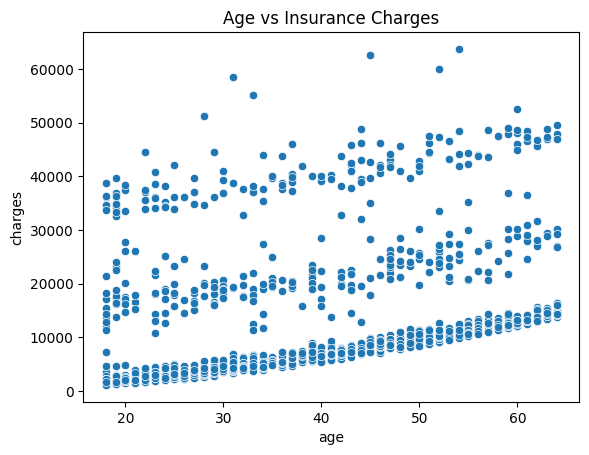

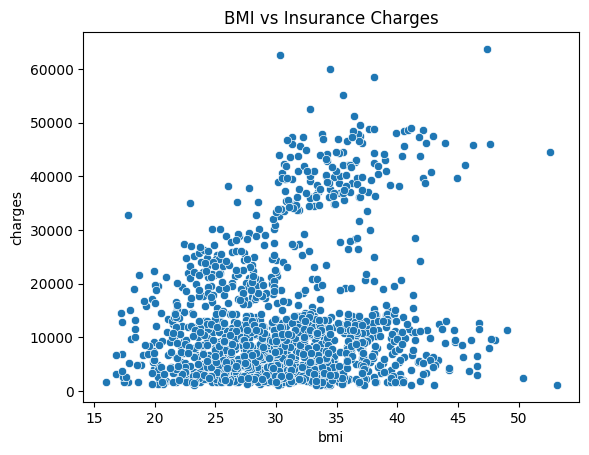

In [13]:
# Plot age against insurance charges
sns.scatterplot(data=df, x='age', y='charges')
plt.title("Age vs Insurance Charges")
plt.show()

# Plot BMI against insurance charges
sns.scatterplot(data=df, x='bmi', y='charges')
plt.title("BMI vs Insurance Charges")
plt.show()

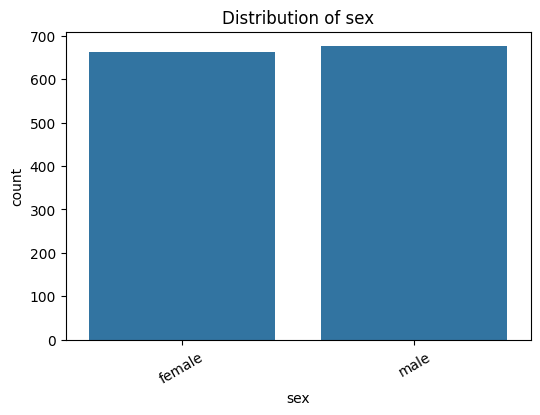

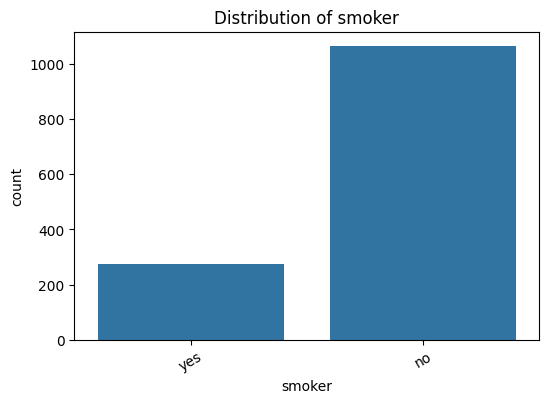

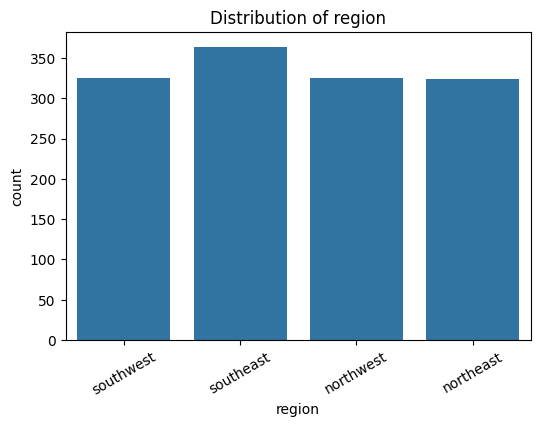

In [14]:
# Plot counts of categorical values
for col in cat_cols:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x=col)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=30)
    plt.show()

In [15]:
# Count missing values in each column
print(df.isnull().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [16]:
# Fill missing numerical values with median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [17]:
# Remove duplicate rows
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicates after:", df.duplicated().sum())

Duplicates before: 1
Duplicates after: 0


In [18]:
# Separate numerical and categorical columns
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include='object').columns.tolist()

print("Numerical variables:", num_cols)
print("Categorical variables:", cat_cols)

Numerical variables: ['age', 'bmi', 'children', 'charges']
Categorical variables: ['sex', 'smoker', 'region']


In [21]:
# Separate input features and target variable
X = df.drop('charges', axis=1)
y = df['charges']

# Convert categorical variables into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Encoded features:")
display(X.head())

print("Target variable:")
print(y.head())

Encoded features:


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0,1,0,0,1
1,18,33.770,1,1,0,0,1,0
2,28,33.000,3,1,0,0,1,0
3,33,22.705,0,1,0,1,0,0
4,32,28.880,0,1,0,1,0,0


Target variable:
0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64


In [22]:
# Display processed dataset dimensions
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

# Check for missing values
print("Missing values in features:", X.isnull().sum().sum())

Feature shape: (1337, 8)
Target shape: (1337,)
Missing values in features: 0


               age       bmi  children   charges
age       1.000000  0.109344  0.041536  0.298308
bmi       0.109344  1.000000  0.012755  0.198401
children  0.041536  0.012755  1.000000  0.067389
charges   0.298308  0.198401  0.067389  1.000000


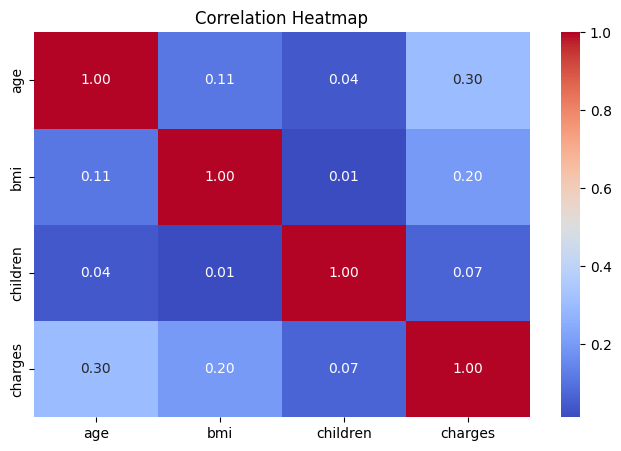

In [23]:
# Calculate correlation between numerical variables
corr = df.select_dtypes(include=np.number).corr()

# Display correlation matrix
print(corr)

# Visualize correlation using a heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

                   age           bmi    children       charges
age         197.243282      9.368233    0.703268  5.073683e+04
bmi           9.368233     37.215715    0.093805  1.465763e+04
children      0.703268      0.093805    1.453402  9.838780e+02
charges   50736.833698  14657.628526  983.878025  1.466608e+08


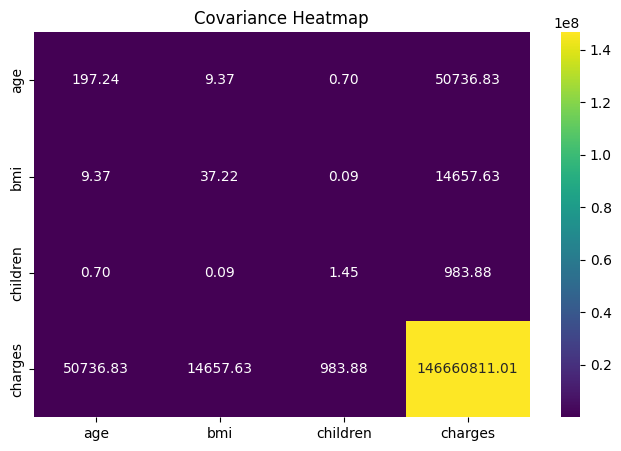

In [24]:
# Calculate covariance between numerical variables
cov = df.select_dtypes(include=np.number).cov()

# Display covariance matrix
print(cov)

# Visualize covariance using a heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(cov, annot=True, cmap='viridis', fmt='.2f')
plt.title("Covariance Heatmap")
plt.show()

In [25]:
# Import train-test split
from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display dataset sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1069, 8)
Testing data: (268, 8)


Correlation Matrix:
               age       bmi  children   charges
age       1.000000  0.109344  0.041536  0.298308
bmi       0.109344  1.000000  0.012755  0.198401
children  0.041536  0.012755  1.000000  0.067389
charges   0.298308  0.198401  0.067389  1.000000


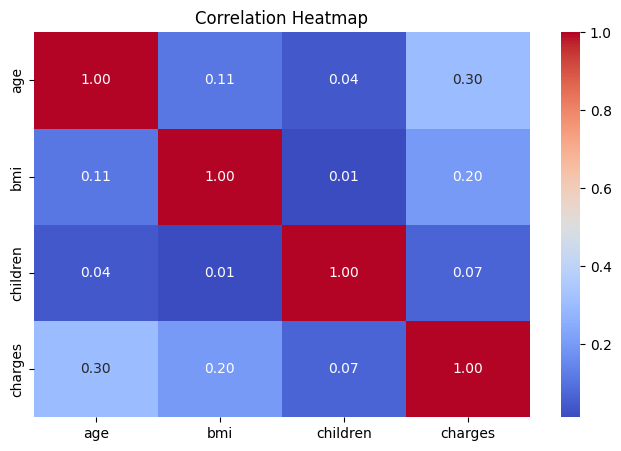

Covariance Matrix:
                   age           bmi    children       charges
age         197.243282      9.368233    0.703268  5.073683e+04
bmi           9.368233     37.215715    0.093805  1.465763e+04
children      0.703268      0.093805    1.453402  9.838780e+02
charges   50736.833698  14657.628526  983.878025  1.466608e+08


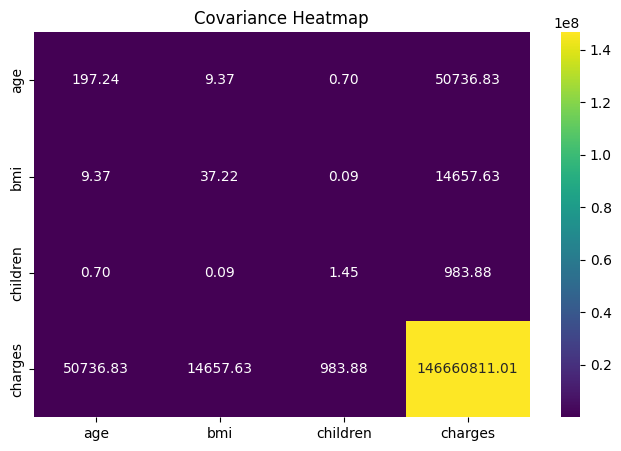

Training data: (1069, 8)
Testing data: (268, 8)


In [26]:
# Step 22: Correlation Analysis
corr = df.select_dtypes(include=np.number).corr()
print("Correlation Matrix:")
print(corr)

# Plot correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

#: Covariance Analysis
cov = df.select_dtypes(include=np.number).cov()
print("Covariance Matrix:")
print(cov)

# Plot covariance heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(cov, annot=True, cmap='viridis', fmt='.2f')
plt.title("Covariance Heatmap")
plt.show()


#: Train-Test Split
from sklearn.model_selection import train_test_split

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display training and testing sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

In [27]:
# Import regression model and evaluation metrics
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train the Multiple Linear Regression model
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predict insurance charges
y_pred_lr = lr.predict(X_test)

# Evaluate model performance
print("Multiple Linear Regression")
print("MAE:", mean_absolute_error(y_test, y_pred_lr))
print("MSE:", mean_squared_error(y_test, y_pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print("R2 Score:", r2_score(y_test, y_pred_lr))

Multiple Linear Regression
MAE: 4177.045561036319
MSE: 35478020.67523561
RMSE: 5956.342894363588
R2 Score: 0.8069287081198011


In [28]:
# Import Ridge Regression
from sklearn.linear_model import Ridge

# Create and train the model
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)

# Predict insurance charges
y_pred_ridge = ridge.predict(X_test)

# Evaluate model performance
print("Ridge Regression")
print("MAE:", mean_absolute_error(y_test, y_pred_ridge))
print("MSE:", mean_squared_error(y_test, y_pred_ridge))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ridge)))
print("R2 Score:", r2_score(y_test, y_pred_ridge))

Ridge Regression
MAE: 4194.009577324494
MSE: 35656880.999075204
RMSE: 5971.338292131439
R2 Score: 0.8059553507246429


In [29]:
# Import Lasso Regression
from sklearn.linear_model import Lasso

# Create and train the model
lasso = Lasso(alpha=1.0, max_iter=10000)
lasso.fit(X_train, y_train)

# Predict insurance charges
y_pred_lasso = lasso.predict(X_test)

# Evaluate model performance
print("Lasso Regression")
print("MAE:", mean_absolute_error(y_test, y_pred_lasso))
print("MSE:", mean_squared_error(y_test, y_pred_lasso))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lasso)))
print("R2 Score:", r2_score(y_test, y_pred_lasso))

Lasso Regression
MAE: 4177.89368126525
MSE: 35491022.53969495
RMSE: 5957.434224537855
R2 Score: 0.8068579520088277


In [30]:
# Import Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor

# Create and train the model
dt = DecisionTreeRegressor(max_depth=5, random_state=42)
dt.fit(X_train, y_train)

# Predict insurance charges
y_pred_dt = dt.predict(X_test)

# Evaluate model performance
print("Decision Tree Regression")
print("MAE:", mean_absolute_error(y_test, y_pred_dt))
print("MSE:", mean_squared_error(y_test, y_pred_dt))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_dt)))
print("R2 Score:", r2_score(y_test, y_pred_dt))

Decision Tree Regression
MAE: 2656.8390786583914
MSE: 19461664.316805515
RMSE: 4411.537636335603
R2 Score: 0.8940896757972968


In [31]:
# Import Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

# Create and train the model
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf.fit(X_train, y_train)

# Predict insurance charges
y_pred_rf = rf.predict(X_test)

# Evaluate model performance
print("Random Forest Regression")
print("MAE:", mean_absolute_error(y_test, y_pred_rf))
print("MSE:", mean_squared_error(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("R2 Score:", r2_score(y_test, y_pred_rf))

Random Forest Regression
MAE: 2637.9945481492537
MSE: 22113000.538090803
RMSE: 4702.4462291546515
R2 Score: 0.8796611113027272


In [32]:
# Store predictions from all five models
models = {
    "Linear Regression": y_pred_lr,
    "Ridge Regression": y_pred_ridge,
    "Lasso Regression": y_pred_lasso,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf
}

# Compare model performance
results = []

for name, pred in models.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2 Score": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results)

# Display results sorted by R2 score
results_df = results_df.sort_values(by="R2 Score", ascending=False)
display(results_df)

# Select the model with the lowest RMSE
best_model_name = results_df.iloc[0]["Model"]
best_model = {
    "Linear Regression": lr,
    "Ridge Regression": ridge,
    "Lasso Regression": lasso,
    "Decision Tree": dt,
    "Random Forest": rf
}[best_model_name]

print("Best model:", best_model_name)

,Model,MAE,RMSE,R2 Score
3,Decision Tree,2656.839079,4411.537636,0.894090
4,Random Forest,2637.994548,4702.446229,0.879661
0,Linear Regression,4177.045561,5956.342894,0.806929
2,Lasso Regression,4177.893681,5957.434225,0.806858
1,Ridge Regression,4194.009577,5971.338292,0.805955


Best model: Decision Tree


In [33]:
# Import Joblib
import joblib

# Save the selected model
joblib.dump(best_model, "best_insurance_model.pkl")

print("Best model saved successfully!")

Best model saved successfully!


In [34]:
# Download the saved model file in Google Colab
from google.colab import files

files.download("best_insurance_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
# Enter details of a new person
age = 30
sex = "male"
bmi = 28.5
children = 1
smoker = "no"
region = "southeast"

# Prepare input using the same features as training
new_person = pd.DataFrame([{
    "age": age,
    "bmi": bmi,
    "children": children,
    "sex_male": 1 if sex == "male" else 0,
    "smoker_yes": 1 if smoker == "yes" else 0,
    "region_northwest": 1 if region == "northwest" else 0,
    "region_southeast": 1 if region == "southeast" else 0,
    "region_southwest": 1 if region == "southwest" else 0
}])

# Match the training feature columns
new_person = new_person.reindex(columns=X.columns, fill_value=0)

# Predict insurance cost
predicted_charge = best_model.predict(new_person)[0]

print(f"Predicted Insurance Cost: ${predicted_charge:.2f}")

Predicted Insurance Cost: $6562.50


In [36]:
# Import widgets for the prediction interface
import ipywidgets as widgets
from IPython.display import display, clear_output

# Create input fields
age_input = widgets.IntSlider(
    value=30, min=18, max=100, description="Age:"
)

sex_input = widgets.Dropdown(
    options=["male", "female"], description="Sex:"
)

bmi_input = widgets.FloatSlider(
    value=28.5, min=15, max=50, step=0.1, description="BMI:"
)

children_input = widgets.IntSlider(
    value=1, min=0, max=5, description="Children:"
)

smoker_input = widgets.Dropdown(
    options=["no", "yes"], description="Smoker:"
)

region_input = widgets.Dropdown(
    options=["southeast", "southwest", "northwest", "northeast"],
    description="Region:"
)

# Create prediction button and output area
predict_button = widgets.Button(
    description="Predict Insurance Cost",
    button_style="success"
)
output = widgets.Output()

# Define prediction action
def predict_cost(button):
    with output:
        clear_output()

        new_person = pd.DataFrame([{
            "age": age_input.value,
            "bmi": bmi_input.value,
            "children": children_input.value,
            "sex_male": 1 if sex_input.value == "male" else 0,
            "smoker_yes": 1 if smoker_input.value == "yes" else 0,
            "region_northwest": 1 if region_input.value == "northwest" else 0,
            "region_southeast": 1 if region_input.value == "southeast" else 0,
            "region_southwest": 1 if region_input.value == "southwest" else 0
        }])

        # Match model training columns
        new_person = new_person.reindex(
            columns=X.columns, fill_value=0
        )

        # Predict the cost
        prediction = best_model.predict(new_person)[0]
        print(f"Predicted Insurance Cost: ${prediction:,.2f}")

# Connect the button to the function
predict_button.on_click(predict_cost)

# Display the interface
display(
    age_input, sex_input, bmi_input,
    children_input, smoker_input, region_input,
    predict_button, output
)

IntSlider(value=30, description='Age:', min=18)

Dropdown(description='Sex:', options=('male', 'female'), value='male')

FloatSlider(value=28.5, description='BMI:', max=50.0, min=15.0)

IntSlider(value=1, description='Children:', max=5)

Dropdown(description='Smoker:', options=('no', 'yes'), value='no')

Dropdown(description='Region:', options=('southeast', 'southwest', 'northwest', 'northeast'), value='southeast…

Button(button_style='success', description='Predict Insurance Cost', style=ButtonStyle())

Output()